# 04 · Gradient Boosting (Tăng cường theo gradient)

**Bài toán:** dự đoán bụi mịn PM2.5 ở giờ kế tiếp (t+1) của cùng một trạm.

**Notebook này làm gì (theo thứ tự):**
1. Nạp dữ liệu, tạo đặc trưng, chia 5 lượt ôn thi thử bằng đúng mã trong `src/` (giống Notebook 02 và 03).
2. Huấn luyện Gradient Boosting trên 5 lượt, chấm điểm bằng MAE, RMSE, R².
3. So sánh với 3 mô hình đã có: Giữ nguyên, Hồi quy tuyến tính, Random Forest.
4. Kiểm tra mô hình có học vẹt không, và sai nhiều ở mùa nào, mức bụi nào.
5. Huấn luyện lần cuối, vẽ biểu đồ, lưu mô hình + điểm + sổ thí nghiệm.

**Gradient Boosting là gì (giải thích ngắn):** nhiều cây quyết định làm việc **nối tiếp**. Cây thứ nhất đoán thô; cây thứ hai học cách đoán **phần sai** của cây thứ nhất; cây thứ ba học cách sửa phần sai còn lại... Dự đoán cuối là tổng cộng dồn của tất cả các cây. (Random Forest thì khác: các cây làm độc lập rồi lấy trung bình.)

**Phiên bản dùng ở đây:** `HistGradientBoostingRegressor` của scikit-learn, là bản nhanh của Gradient Boosting (gom giá trị số vào các "thùng" trước khi chia cây). Bản chuẩn `GradientBoostingRegressor` chậm hơn khoảng 6 lần trên dữ liệu này; README của nhóm cho phép dùng phương án nhanh hơn nếu bản chuẩn quá chậm, nhưng **phải ghi rõ lý do này trong báo cáo**.

**Quy tắc phải giữ:**
- Chỉ dùng 5 lượt ôn thi thử để chấm điểm. **Không dùng tập Test** để chọn hay chỉnh mô hình.
- Cấu hình (tham số) được đặt cố định ở mục 4; **chưa tinh chỉnh** (RandomizedSearchCV là bước sau).
- Cùng 27 đặc trưng, cùng 5 lượt chia, cùng hạt giống 42 như các mô hình khác, để so sánh công bằng.

**Cách chạy:** chọn *Run All*. Cần có sẵn các file do notebook 02 và 03 tạo ra (`outputs/baseline_comparison_merged.csv`, `outputs/random_forest_cv_metrics.csv`).

## 1. Cấu hình và nạp thư viện

Hai "công tắc" quan trọng ở ô dưới:
- `SAVE_ARTIFACTS`: `True` thì ghi mô hình, điểm, biểu đồ ra file; `False` thì chỉ chạy để xem, không ghi gì (an toàn khi đang thử nghiệm).
- `SAVE_OOF`: `True` thì lưu thêm file dự đoán từng dòng (khoảng 28 MB). Tắt nếu không muốn file nặng trong Git.

In [1]:
import json
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Tìm thư mục gốc của đồ án (thư mục chứa src/), chạy được từ gốc hoặc từ notebooks/.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [CURRENT_DIR, *CURRENT_DIR.parents] if (path / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (thư mục chứa src/).")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Dùng lại mã chung của nhóm (không tự viết lại cách chia dữ liệu).
from src.data_loader import load_data, time_split, cv_folds, TEST_START
from src.features import (
    FEATURE_COLUMNS,
    FFILL_LIMIT,
    PM25_LAGS,
    ROLLING_WINDOWS,
    add_features,
    build_preprocessor,
    split_xy,
)

RANDOM_STATE = 42       # hạt giống: cố định để ai chạy lại cũng ra đúng kết quả
SAVE_ARTIFACTS = True   # True: ghi file kết quả; False: chỉ chạy xem
SAVE_OOF = True         # True: lưu file dự đoán chi tiết (~28 MB)

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

# Đồng bộ kiểu biểu đồ với Notebook 02 và 03.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

SAVED_FIGURES = []


def save_figure(fig, filename):
    """Lưu biểu đồ PNG vào outputs/figures khi SAVE_ARTIFACTS=True."""
    if SAVE_ARTIFACTS:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        figure_path = FIGURES_DIR / filename
        fig.savefig(figure_path, dpi=150, bbox_inches="tight")
        SAVED_FIGURES.append(figure_path)
        print("Đã lưu hình:", figure_path.relative_to(PROJECT_ROOT))
    return fig


print("Thư mục gốc dự án:", PROJECT_ROOT)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("Mốc bắt đầu Test:", TEST_START)
print("SAVE_ARTIFACTS =", SAVE_ARTIFACTS, "| SAVE_OOF =", SAVE_OOF)

Thư mục gốc dự án: C:\Users\Admin\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027
scikit-learn: 1.7.2
pandas: 2.3.3
Mốc bắt đầu Test: 2016-09-01 00:00:00
SAVE_ARTIFACTS = True | SAVE_OOF = True


## 2. Nạp dữ liệu và tạo đặc trưng

Cùng quy trình với Notebook 02 và 03:
- `add_features` tạo **cột đáp án `target`** (bụi PM2.5 của giờ kế tiếp, cùng trạm) và các **đặc trưng** (bụi các giờ trước, trung bình trượt, giờ/tháng/thứ dạng sin-cos).
- Những dòng thiếu `target` bị **bỏ**, không điền bừa đáp án.

In [2]:
raw = load_data()
featured = add_features(raw)
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)

print(f"Dữ liệu gốc            : {raw.shape[0]:,} dòng x {raw.shape[1]} cột")
print(f"Sau khi tạo đặc trưng  : {featured.shape[0]:,} dòng x {featured.shape[1]} cột")
print(f"Sau khi bỏ dòng thiếu target: {labeled.shape[0]:,} dòng")
print(f"Số trạm                : {labeled['station'].nunique()}")
print(f"Số đặc trưng đưa vào mô hình: {len(FEATURE_COLUMNS)}")

Dữ liệu gốc            : 420,768 dòng x 19 cột
Sau khi tạo đặc trưng  : 420,768 dòng x 35 cột
Sau khi bỏ dòng thiếu target: 412,017 dòng
Số trạm                : 12
Số đặc trưng đưa vào mô hình: 27


## 3. Chia dữ liệu và tạo đúng 5 lượt ôn thi thử

- **Phần học/ôn thi thử** (target đến hết tháng 8/2016) và **phần thi cuối** (từ 01/09/2016) được chia theo thời gian.
- Phần học được cắt tiếp thành **5 lượt** (gọi là *fold*): mỗi lượt học từ dữ liệu cũ rồi thử trên đoạn **sau đó** về mặt thời gian.
- Các ô `assert` ở cuối để chắc chắn không dữ liệu thi nào lọt vào phần học.

In [3]:
train_validation, test = time_split(labeled)
train_validation = train_validation.reset_index(drop=True)
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)   # X = đề bài (27 đặc trưng), y = đáp án (target)
folds = cv_folds(train_validation, n_splits=5)

# Bảng thời gian và kích thước từng lượt.
fold_rows = []
for fold_id, (tr, va) in enumerate(folds, start=1):
    train_times = train_validation.iloc[tr]["target_datetime"]
    validation_times = train_validation.iloc[va]["target_datetime"]
    fold_rows.append({
        "fold": fold_id,
        "train_rows": len(tr),
        "validation_rows": len(va),
        "train_start": train_times.min(),
        "train_end": train_times.max(),
        "validation_start": validation_times.min(),
        "validation_end": validation_times.max(),
    })

fold_table = pd.DataFrame(fold_rows)
display(fold_table)

assert len(folds) == 5, f"Cần đúng 5 lượt, hiện có {len(folds)}."
assert train_validation["target_datetime"].max() < TEST_START
assert test["target_datetime"].min() >= TEST_START
for tr, va in folds:
    assert np.intersect1d(tr, va).size == 0, "Phần học và phần thử bị trùng dòng."
    assert (
        train_validation.iloc[tr]["target_datetime"].max()
        < train_validation.iloc[va]["target_datetime"].min()
    ), "Phần thử không nằm sau phần học."

print(f"Phần học/ôn thi thử: {len(train_validation):,} dòng")
print(f"Phần thi cuối      : {len(test):,} dòng (giữ riêng, không dùng trong notebook này)")
print("Kiểm tra thứ tự thời gian và 5 lượt: PASS")

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,1,60258,60595,2013-03-01 01:00:00,2013-09-30 00:00:00,2013-09-30 01:00:00,2014-05-01 17:00:00
1,2,120853,59958,2013-03-01 01:00:00,2014-05-01 17:00:00,2014-05-01 18:00:00,2014-11-30 16:00:00
2,3,180811,59858,2013-03-01 01:00:00,2014-11-30 16:00:00,2014-11-30 17:00:00,2015-07-02 02:00:00
3,4,240669,60217,2013-03-01 01:00:00,2015-07-02 02:00:00,2015-07-02 03:00:00,2016-01-31 14:00:00
4,5,300886,60068,2013-03-01 01:00:00,2016-01-31 14:00:00,2016-01-31 15:00:00,2016-08-31 23:00:00


Phần học/ôn thi thử: 360,954 dòng
Phần thi cuối      : 51,063 dòng (giữ riêng, không dùng trong notebook này)
Kiểm tra thứ tự thời gian và 5 lượt: PASS


## 4. Khởi tạo Gradient Boosting

**Tham số** là các "nút vặn" người làm phải đặt trước khi cho máy học. Ở đây đặt cố định, **chưa tinh chỉnh**:

| Tham số | Giá trị | Ý nghĩa dễ hiểu |
|---|---:|---|
| `max_iter` | 200 | Số cây nối tiếp (mỗi vòng thêm một cây sửa lỗi) |
| `learning_rate` | 0,1 | Mỗi cây chỉ sửa khoảng 10% phần sai còn lại. Nhỏ thì học chậm nhưng ổn định hơn |
| `early_stopping` | False | **Tắt tự dừng sớm**. Mặc định bản này tự dừng khi dữ liệu trên 10.000 dòng; ở đây giữ cố định đúng 200 vòng để thí nghiệm lặp lại được và so sánh công bằng |
| `random_state` | 42 | Hạt giống |

Các tham số khác (ví dụ số lá tối đa của mỗi cây = 31, số mẫu tối thiểu mỗi lá = 20) để **mặc định** của thư viện.

Dây chuyền gồm 2 bước nối nhau: (1) tiền xử lý (điền ô trống, thêm cờ "ô này vốn thiếu", mã hóa tên trạm/hướng gió thành cột 0/1); (2) Gradient Boosting. Tiền xử lý chỉ học từ **phần học của từng lượt**, nên không nhìn trộm phần thử. Gradient Boosting dựa trên cây nên không cần chuẩn hóa thang đo (`scale=False`).

In [4]:
GB_PARAMS = {
    "max_iter": 200,          # số cây nối tiếp
    "learning_rate": 0.1,     # mỗi cây sửa ~10% phần sai còn lại
    "early_stopping": False,  # giữ cố định đúng 200 vòng
    "random_state": RANDOM_STATE,
}


def make_gradient_boosting():
    return Pipeline([
        ("prep", build_preprocessor(scale=False)),
        ("model", HistGradientBoostingRegressor(**GB_PARAMS)),
    ])


display(pd.Series(GB_PARAMS, name="giá trị").to_frame())

,giá trị
max_iter,200
learning_rate,0.1
early_stopping,False
random_state,42


## 5. Hàm chấm điểm

- **MAE**: mức lệch trung bình giữa số đoán và số thật (µg/m³). Càng nhỏ càng tốt.
- **RMSE**: giống MAE nhưng **phạt nặng các lần sai lớn**. Đây là thước đo chính của đồ án.
- **R²**: mô hình giải thích được bao nhiêu phần sự lên xuống của bụi. Gần 1 là tốt.

In [5]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
    }

## 6. Huấn luyện và chấm điểm trên 5 lượt

Với mỗi lượt:
1. Tạo một mô hình **mới tinh**.
2. **Huấn luyện** (`fit`) chỉ trên phần học của lượt đó.
3. **Dự đoán** (`predict`) phần thử, rồi **chấm điểm** so với đáp án thật.
4. Chấm thêm cả trên **chính phần học** (`train_rmse`) để kiểm tra học vẹt ở mục 9.
5. Lưu dự đoán từng dòng (OOF, tức dự đoán trên dữ liệu mà mô hình chưa từng học) để phân tích sai ở mục 10.

In [6]:
fold_results = []
cv_models = []
oof_predictions = []   # chỉ chứa dự đoán trên phần thử; không chứa Test

cv_start_time = time.perf_counter()
for fold_id, (tr, va) in enumerate(folds, start=1):
    X_train, y_train = X_tv.iloc[tr], y_tv.iloc[tr]
    X_val, y_val = X_tv.iloc[va], y_tv.iloc[va]

    model = make_gradient_boosting()
    fold_start_time = time.perf_counter()
    model.fit(X_train, y_train)            # HỌC
    predictions = model.predict(X_val)     # ĐOÁN phần thử
    elapsed = time.perf_counter() - fold_start_time

    metrics = regression_metrics(y_val, predictions)                    # CHẤM phần thử
    train_rmse = regression_metrics(y_train, model.predict(X_train))["rmse"]  # CHẤM phần học
    n_vong = int(model.named_steps["model"].n_iter_)

    fold_results.append({
        "fold": fold_id,
        **metrics,
        "runtime_seconds": float(elapsed),
        "train_rows": int(len(tr)),
        "validation_rows": int(len(va)),
        "train_rmse": float(train_rmse),
    })
    cv_models.append(model)

    oof_part = train_validation.iloc[va][
        ["station", "datetime", "target_datetime"]
    ].reset_index(drop=True).copy()
    oof_part.insert(0, "fold", fold_id)
    oof_part["y_true"] = y_val.to_numpy()
    oof_part["y_pred"] = predictions
    oof_predictions.append(oof_part)

    print(
        f"Lượt {fold_id}/5 | MAE={metrics['mae']:.4f} | RMSE={metrics['rmse']:.4f} | "
        f"R2={metrics['r2']:.4f} | số vòng={n_vong} | {elapsed:.1f} giây"
    )

cv_total_runtime_seconds = time.perf_counter() - cv_start_time
gb_cv_metrics = pd.DataFrame(fold_results)
gb_oof = pd.concat(oof_predictions, ignore_index=True)
gb_oof["residual"] = gb_oof["y_true"] - gb_oof["y_pred"]   # thật - đoán; dương = đoán THẤP hơn thực tế

print("\nKết quả từng lượt:")
display(gb_cv_metrics)
print(f"Tổng thời gian 5 lượt: {cv_total_runtime_seconds:.1f} giây")

Lượt 1/5 | MAE=17.4333 | RMSE=37.1143 | R2=0.8343 | số vòng=200 | 8.3 giây
Lượt 2/5 | MAE=9.1332 | RMSE=15.6712 | R2=0.9516 | số vòng=200 | 4.0 giây
Lượt 3/5 | MAE=10.1589 | RMSE=18.7924 | R2=0.9325 | số vòng=200 | 4.6 giây
Lượt 4/5 | MAE=10.0413 | RMSE=20.3364 | R2=0.9520 | số vòng=200 | 7.1 giây
Lượt 5/5 | MAE=8.6048 | RMSE=17.9484 | R2=0.9160 | số vòng=200 | 7.0 giây

Kết quả từng lượt:


,fold,mae,rmse,r2,runtime_seconds,train_rows,validation_rows,train_rmse
0,1,17.433278,37.114265,0.834283,8.340007,60258,60595,14.633029
1,2,9.133196,15.671229,0.951627,3.976876,120853,59958,16.775440
2,3,10.158873,18.792374,0.932477,4.603692,180811,59858,16.058463
3,4,10.041292,20.336446,0.951950,7.148822,240669,60217,16.375579
4,5,8.604786,17.948443,0.916011,7.045825,300886,60068,16.431378


Tổng thời gian 5 lượt: 37.2 giây


## 7. Tổng hợp kết quả 5 lượt

Trung bình và độ lệch chuẩn (độ dao động giữa các lượt; lớn nghĩa là kết quả không ổn định). Đây là trung bình **không trọng số theo lượt**, cùng cách tính với Notebook 02 và 03.

In [7]:
gb_cv_summary = pd.DataFrame([
    {
        "metric": metric.upper(),
        "mean": float(gb_cv_metrics[metric].mean()),
        "std": float(gb_cv_metrics[metric].std(ddof=1)),
    }
    for metric in ["mae", "rmse", "r2"]
])
display(gb_cv_summary)

,metric,mean,std
0,MAE,11.074285,3.612758
1,RMSE,21.972551,8.630788
2,R2,0.917270,0.048741


## 8. So sánh với 3 mô hình khác (trên cùng 5 lượt)

Điểm của Giữ nguyên và Hồi quy tuyến tính lấy từ `outputs/baseline_comparison_merged.csv` (do notebook 02 tạo). Điểm Random Forest lấy từ `outputs/random_forest_cv_metrics.csv` (do notebook 03 tạo). Con số càng **thấp** càng tốt.

Có thêm dòng **"Trung bình lượt 2-5"** vì lượt 1 có phần học chỉ gồm tháng 3 đến tháng 9/2013 (chưa có mùa đông), nên rất khác các lượt còn lại.

In [8]:
baseline_path = OUTPUTS_DIR / "baseline_comparison_merged.csv"
rf_path = OUTPUTS_DIR / "random_forest_cv_metrics.csv"
assert baseline_path.is_file(), "Thiếu outputs/baseline_comparison_merged.csv - hãy chạy notebook 02 trước."
assert rf_path.is_file(), "Thiếu outputs/random_forest_cv_metrics.csv - hãy chạy notebook 03 trước."

baseline = pd.read_csv(baseline_path, encoding="utf-8-sig")
baseline_folds = baseline[baseline["scope"] == "cv_fold"].copy()
baseline_folds["fold"] = baseline_folds["group"].str.extract(r"(\d+)")[0].astype(int)
baseline_folds = baseline_folds.set_index("fold").sort_index()

rf_by_fold = pd.read_csv(rf_path, encoding="utf-8-sig").set_index("fold")
gb_by_fold = gb_cv_metrics.set_index("fold")

CAC_MO_HINH = ["Giữ nguyên", "Hồi quy tuyến tính", "Random Forest", "Gradient Boosting"]


def bang_so_sanh(metric):
    bang = pd.DataFrame({
        "Giữ nguyên": baseline_folds[f"{metric}_P"],
        "Hồi quy tuyến tính": baseline_folds[f"{metric}_LR"],
        "Random Forest": rf_by_fold[metric],
        "Gradient Boosting": gb_by_fold[metric],
    })
    tb_5_luot = bang.mean()
    tb_luot_2_5 = bang.loc[2:5].mean()
    bang.loc["Trung bình 5 lượt"] = tb_5_luot
    bang.loc["Trung bình lượt 2-5"] = tb_luot_2_5
    bang["Tốt nhất"] = bang[CAC_MO_HINH].idxmin(axis=1)
    return bang.round(2)


bang_rmse = bang_so_sanh("rmse")
bang_mae = bang_so_sanh("mae")
print("RMSE theo từng lượt (càng thấp càng tốt):")
display(bang_rmse)
print("MAE theo từng lượt (càng thấp càng tốt):")
display(bang_mae)

RMSE theo từng lượt (càng thấp càng tốt):


,Giữ nguyên,Hồi quy tuyến tính,Random Forest,Gradient Boosting,Tốt nhất
fold,,,,,
1,24.15,23.39,29.89,37.11,Hồi quy tuyến tính
2,17.21,16.81,16.05,15.67,Gradient Boosting
3,20.83,20.06,18.99,18.79,Gradient Boosting
4,19.62,18.84,18.64,20.34,Random Forest
5,18.02,17.37,17.29,17.95,Random Forest
Trung bình 5 lượt,19.97,19.29,20.17,21.97,Hồi quy tuyến tính
Trung bình lượt 2-5,18.92,18.27,17.74,18.19,Random Forest


MAE theo từng lượt (càng thấp càng tốt):


,Giữ nguyên,Hồi quy tuyến tính,Random Forest,Gradient Boosting,Tốt nhất
fold,,,,,
1,12.74,13.22,14.94,17.43,Giữ nguyên
2,9.49,9.81,9.20,9.13,Gradient Boosting
3,10.78,11.07,10.18,10.16,Gradient Boosting
4,10.11,10.34,9.76,10.04,Random Forest
5,9.01,9.25,8.55,8.60,Random Forest
Trung bình 5 lượt,10.42,10.74,10.53,11.07,Giữ nguyên
Trung bình lượt 2-5,9.85,10.12,9.42,9.48,Random Forest


## 9. Kiểm tra học vẹt (overfit)

**Học vẹt** là khi mô hình học thuộc dữ liệu cũ nên làm bài cũ rất giỏi nhưng làm bài mới thì kém. Gradient Boosting dễ bị hơn Random Forest nếu để quá nhiều vòng hoặc học quá mạnh.

Cách kiểm tra: so sai số trên **phần học** (`train_rmse`) với sai số trên **phần thử** (`rmse`). Nếu phần thử cao hơn rất nhiều (tỉ lệ lớn) thì đáng ngờ.

In [9]:
overfit = gb_cv_metrics[["fold", "train_rmse", "rmse"]].rename(
    columns={"train_rmse": "RMSE phần học", "rmse": "RMSE phần thử"}
)
overfit["Tỉ lệ thử / học"] = (overfit["RMSE phần thử"] / overfit["RMSE phần học"]).round(2)
display(overfit.round(2))

,fold,RMSE phần học,RMSE phần thử,Tỉ lệ thử / học
0,1,14.63,37.11,2.54
1,2,16.78,15.67,0.93
2,3,16.06,18.79,1.17
3,4,16.38,20.34,1.24
4,5,16.43,17.95,1.09


## 10. Sai nhiều ở mùa nào, mức bụi nào

Dùng file dự đoán OOF vừa tạo (`gb_oof`). `residual` = thật - đoán, nên **dương nghĩa là mô hình đoán thấp hơn thực tế**. Nếu có file OOF của Random Forest thì đặt cạnh để so sánh.

In [10]:
MUA = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Xuân",
       6: "Hè", 7: "Hè", 8: "Hè", 9: "Thu", 10: "Thu", 11: "Thu"}
MUC_BUI_CAN = [-1, 35, 75, 115, 150, 250, 1e9]
MUC_BUI_NHAN = ["0-35", "35-75", "75-115", "115-150", "150-250", ">250"]


def them_nhom(df):
    df = df.copy()
    df["mua"] = df["target_datetime"].dt.month.map(MUA)
    df["muc_bui"] = pd.cut(df["y_true"], bins=MUC_BUI_CAN, labels=MUC_BUI_NHAN)
    return df


def tom_tat(df, cot_nhom):
    df = df.assign(binh_phuong=df["residual"] ** 2)
    g = df.groupby(cot_nhom, observed=True)
    return pd.DataFrame({
        "Số dòng": g.size(),
        "Bụi trung bình": g["y_true"].mean(),
        "RMSE": np.sqrt(g["binh_phuong"].mean()),
        "Sai lệch TB (dương = đoán thấp)": g["residual"].mean(),
    }).round(1)


gb_nhom = them_nhom(gb_oof)
print("Gradient Boosting - sai số theo MÙA (cả 5 lượt):")
display(tom_tat(gb_nhom, "mua"))
print("Gradient Boosting - sai số theo MỨC BỤI (cả 5 lượt):")
display(tom_tat(gb_nhom, "muc_bui"))
print("Gradient Boosting - lượt 1, theo mùa:")
display(tom_tat(gb_nhom[gb_nhom["fold"] == 1], "mua"))

# So sánh với Random Forest (nếu có file OOF của notebook 03).
rf_oof_path = OUTPUTS_DIR / "random_forest_validation_oof_predictions.csv"
rf_nhom = None
if rf_oof_path.is_file():
    rf_oof = pd.read_csv(
        rf_oof_path,
        usecols=["fold", "target_datetime", "y_true", "y_pred", "residual"],
        parse_dates=["target_datetime"],
        encoding="utf-8-sig",
    )
    rf_nhom = them_nhom(rf_oof)
    for ten, cot in [("MÙA", "mua"), ("MỨC BỤI", "muc_bui")]:
        so_sanh = pd.DataFrame({
            "RMSE Random Forest": tom_tat(rf_nhom, cot)["RMSE"],
            "RMSE Gradient Boosting": tom_tat(gb_nhom, cot)["RMSE"],
        })
        print(f"So sánh RMSE theo {ten}:")
        display(so_sanh)
else:
    print("Không thấy file OOF của Random Forest, bỏ qua phần so sánh.")

Gradient Boosting - sai số theo MÙA (cả 5 lượt):


,Số dòng,Bụi trung bình,RMSE,Sai lệch TB (dương = đoán thấp)
mua,,,,
Hè,77813,60.7,12.9,-0.2
Thu,68918,84.6,17.2,0.6
Xuân,77638,74.9,18.1,0.5
Đông,76327,92.2,37.1,6.6


Gradient Boosting - sai số theo MỨC BỤI (cả 5 lượt):


,Số dòng,Bụi trung bình,RMSE,Sai lệch TB (dương = đoán thấp)
muc_bui,,,,
0-35,115085,16.5,10.0,-2.6
35-75,72055,54.2,13.9,-1.5
75-115,45799,93.7,16.7,1.5
115-150,24358,131.5,21.0,4.2
150-250,30226,191.0,30.8,9.7
>250,13173,328.9,80.9,38.5


Gradient Boosting - lượt 1, theo mùa:


,Số dòng,Bụi trung bình,RMSE,Sai lệch TB (dương = đoán thấp)
mua,,,,
Thu,17744,84.0,18.2,1.3
Xuân,17498,93.6,20.9,0.5
Đông,25353,106.5,52.5,18.2


So sánh RMSE theo MÙA:


,RMSE Random Forest,RMSE Gradient Boosting
mua,,
Hè,13.1,12.9
Thu,17.1,17.2
Xuân,18.1,18.1
Đông,30.5,37.1


So sánh RMSE theo MỨC BỤI:


,RMSE Random Forest,RMSE Gradient Boosting
muc_bui,,
0-35,10.7,10.0
35-75,14.8,13.9
75-115,17.1,16.7
115-150,20.7,21.0
150-250,26.7,30.8
>250,65.0,80.9


## 11. Huấn luyện mô hình cuối trên toàn bộ phần học

Sau khi xong 5 lượt, huấn luyện **một mô hình cuối** trên toàn bộ phần học để lưu dùng về sau. **Không dự đoán hay chấm điểm trên Test ở notebook này**; Test chỉ được mở một lần ở bước đánh giá cuối, sau khi nhóm đã chọn và khóa mô hình.

In [11]:
final_gb_model = make_gradient_boosting()

final_fit_start = time.perf_counter()
final_gb_model.fit(X_tv, y_tv)
final_fit_seconds = time.perf_counter() - final_fit_start

print(f"Đã huấn luyện mô hình cuối trên {len(X_tv):,} dòng.")
print(f"Thời gian huấn luyện mô hình cuối: {final_fit_seconds:.2f} giây.")
print("Test chưa được dự đoán, chấm điểm hay dùng để chọn cấu hình.")

Đã huấn luyện mô hình cuối trên 360,954 dòng.
Thời gian huấn luyện mô hình cuối: 7.56 giây.
Test chưa được dự đoán, chấm điểm hay dùng để chọn cấu hình.


## 12. Biểu đồ

Bốn biểu đồ, đều chỉ dùng kết quả trên phần thử (không dùng Test):
1. RMSE từng lượt của cả 4 mô hình.
2. Số đoán so với số thật (càng gần đường đỏ càng chính xác).
3. Phân bố độ lệch (thật - đoán).
4. RMSE theo mức bụi (Random Forest đặt cạnh nếu có).

*Biểu đồ "độ quan trọng của đặc trưng" không có ở đây vì bản `HistGradientBoostingRegressor` không có sẵn chỉ số này. Nếu cần có thể dùng `permutation_importance` ở bước sau.*

Đã lưu hình: outputs\figures\gradient_boosting_cv_rmse_by_fold.png


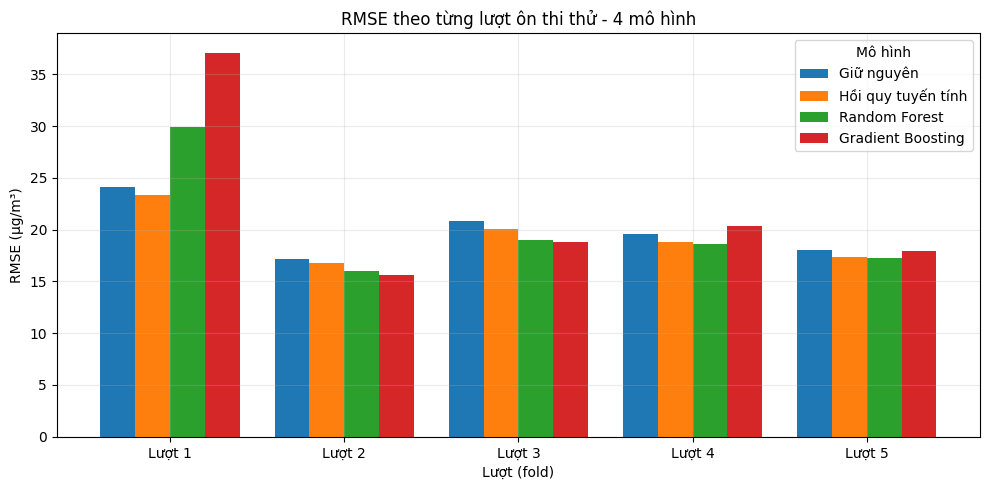

Đã lưu hình: outputs\figures\gradient_boosting_pred_vs_actual.png


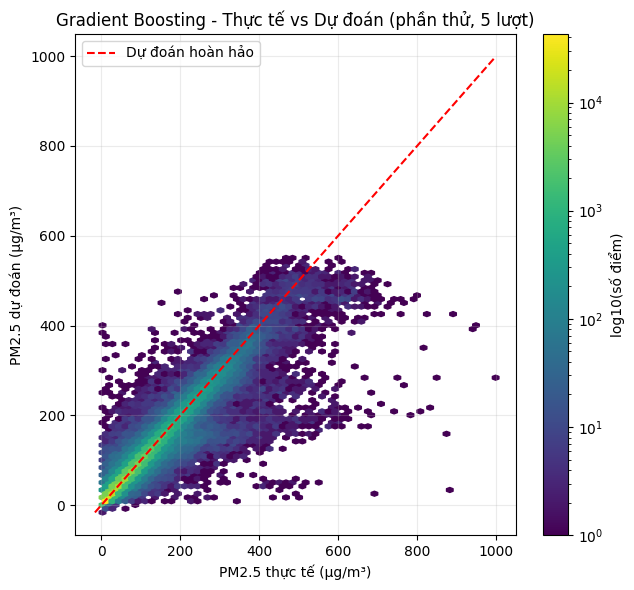

Đã lưu hình: outputs\figures\gradient_boosting_residuals.png


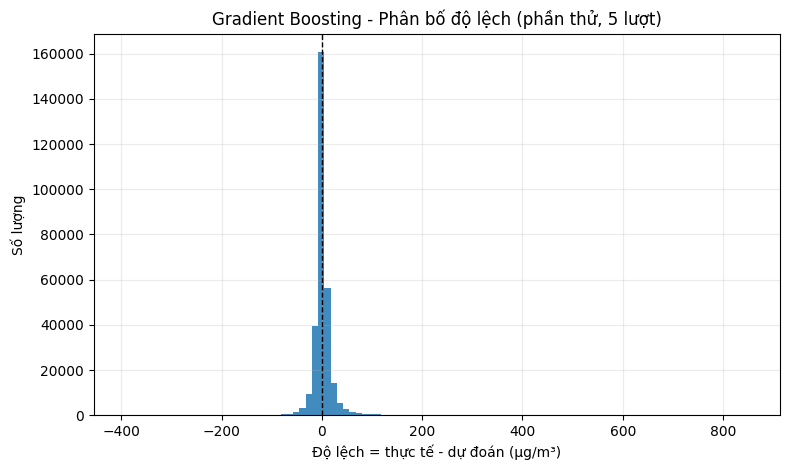

Đã lưu hình: outputs\figures\gradient_boosting_rmse_by_pm25_level.png


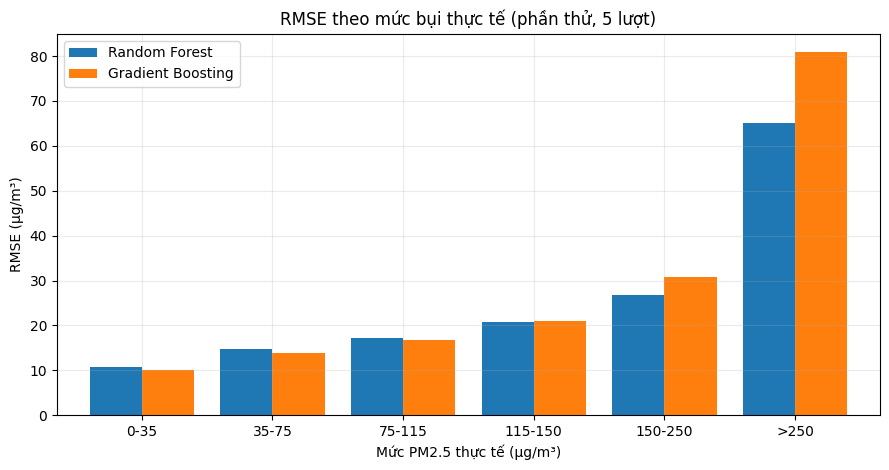

Số hình đã lưu: 4


In [12]:
# 1) RMSE từng lượt của 4 mô hình.
du_lieu_cot = bang_rmse.loc[[1, 2, 3, 4, 5], CAC_MO_HINH]
fig, ax = plt.subplots(figsize=(10, 5))
du_lieu_cot.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("RMSE theo từng lượt ôn thi thử - 4 mô hình")
ax.set_xlabel("Lượt (fold)")
ax.set_ylabel("RMSE (µg/m³)")
ax.set_xticklabels([f"Lượt {i}" for i in du_lieu_cot.index], rotation=0)
ax.legend(title="Mô hình")
fig.tight_layout()
save_figure(fig, "gradient_boosting_cv_rmse_by_fold.png")
plt.show()
plt.close(fig)

# 2) Số đoán so với số thật (gộp 5 lượt).
gia_tri_min = float(min(gb_oof["y_true"].min(), gb_oof["y_pred"].min()))
gia_tri_max = float(max(gb_oof["y_true"].max(), gb_oof["y_pred"].max()))
fig, ax = plt.subplots(figsize=(6.5, 6))
hex_plot = ax.hexbin(
    gb_oof["y_true"], gb_oof["y_pred"],
    gridsize=60, bins="log", mincnt=1, cmap="viridis",
)
ax.plot([gia_tri_min, gia_tri_max], [gia_tri_min, gia_tri_max], "r--", linewidth=1.5, label="Dự đoán hoàn hảo")
ax.set_title("Gradient Boosting - Thực tế vs Dự đoán (phần thử, 5 lượt)")
ax.set_xlabel("PM2.5 thực tế (µg/m³)")
ax.set_ylabel("PM2.5 dự đoán (µg/m³)")
fig.colorbar(hex_plot, ax=ax, label="log10(số điểm)")
ax.legend()
fig.tight_layout()
save_figure(fig, "gradient_boosting_pred_vs_actual.png")
plt.show()
plt.close(fig)

# 3) Phân bố độ lệch.
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(gb_oof["residual"], bins=100, alpha=0.85)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Gradient Boosting - Phân bố độ lệch (phần thử, 5 lượt)")
ax.set_xlabel("Độ lệch = thực tế - dự đoán (µg/m³)")
ax.set_ylabel("Số lượng")
fig.tight_layout()
save_figure(fig, "gradient_boosting_residuals.png")
plt.show()
plt.close(fig)

# 4) RMSE theo mức bụi.
cot_muc_bui = pd.DataFrame({"Gradient Boosting": tom_tat(gb_nhom, "muc_bui")["RMSE"]})
if rf_nhom is not None:
    cot_muc_bui.insert(0, "Random Forest", tom_tat(rf_nhom, "muc_bui")["RMSE"])
fig, ax = plt.subplots(figsize=(9, 4.8))
cot_muc_bui.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("RMSE theo mức bụi thực tế (phần thử, 5 lượt)")
ax.set_xlabel("Mức PM2.5 thực tế (µg/m³)")
ax.set_ylabel("RMSE (µg/m³)")
ax.set_xticklabels(cot_muc_bui.index, rotation=0)
fig.tight_layout()
save_figure(fig, "gradient_boosting_rmse_by_pm25_level.png")
plt.show()
plt.close(fig)

print(f"Số hình đã lưu: {len(SAVED_FIGURES)}")

## 13. Lưu mô hình, điểm và sổ thí nghiệm

Tất cả file đều có tên bắt đầu bằng `gradient_boosting`, **không ghi đè** lên kết quả của Random Forest hay baseline. Dòng mới trong `experiment_log.csv` có mã `gradient_boosting_cv5`; chạy lại thì dòng này được **thay thế** chứ không thêm trùng, các dòng khác giữ nguyên.

In [13]:
DATASET_VERSION = (
    f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
    f"lags={'/'.join(map(str, PM25_LAGS))}; "
    f"rolling={'/'.join(map(str, ROLLING_WINDOWS))}"
)

if SAVE_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

    model_path = MODELS_DIR / "gradient_boosting.joblib"
    metrics_path = OUTPUTS_DIR / "gradient_boosting_cv_metrics.csv"
    summary_path = OUTPUTS_DIR / "gradient_boosting_cv_summary.csv"
    oof_path = OUTPUTS_DIR / "gradient_boosting_validation_oof_predictions.csv"
    metadata_path = MODELS_DIR / "gradient_boosting_metadata.json"

    joblib.dump(final_gb_model, model_path, compress=3)
    gb_cv_metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")
    gb_cv_summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
    if SAVE_OOF:
        gb_oof.to_csv(oof_path, index=False, encoding="utf-8-sig")

    metadata = {
        "model": "HistGradientBoostingRegressor",
        "pipeline": "build_preprocessor(scale=False) + HistGradientBoostingRegressor",
        "reason_for_hist_version": "Bản chuẩn GradientBoostingRegressor chậm hơn nhiều trên dữ liệu này; dùng bản nhanh cùng họ.",
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "python_version": sys.version.split()[0],
        "sklearn_version": sklearn.__version__,
        "pandas_version": pd.__version__,
        "target": "PM2.5 at t+1 (same station)",
        "dataset_version": DATASET_VERSION,
        "train_validation_rows": int(len(X_tv)),
        "train_validation_target_period": [
            str(train_validation["target_datetime"].min()),
            str(train_validation["target_datetime"].max()),
        ],
        "test_start": str(TEST_START),
        "test_rows_reserved": int(len(test)),
        "test_used_for_tuning": False,
        "test_evaluated": False,
        "feature_columns": list(FEATURE_COLUMNS),
        "random_state": RANDOM_STATE,
        "gradient_boosting_params": GB_PARAMS,
        "cv": "TimeSeriesSplit expanding window, 5 folds, grouped by target_datetime; same src.cv_folds as Notebook 02",
        "cv_fold_overview": json.loads(
            fold_table.assign(**{
                column: fold_table[column].astype(str)
                for column in ["train_start", "train_end", "validation_start", "validation_end"]
            }).to_json(orient="records")
        ),
        "cv_fold_metrics": json.loads(gb_cv_metrics.to_json(orient="records")),
        "cv_metrics_mean": {m: float(gb_cv_metrics[m].mean()) for m in ["mae", "rmse", "r2"]},
        "cv_metrics_std": {m: float(gb_cv_metrics[m].std(ddof=1)) for m in ["mae", "rmse", "r2"]},
        "cv_total_runtime_seconds": float(cv_total_runtime_seconds),
        "final_fit_seconds": float(final_fit_seconds),
        "saved_outputs": {
            "model": str(model_path.relative_to(PROJECT_ROOT)),
            "cv_metrics": str(metrics_path.relative_to(PROJECT_ROOT)),
            "cv_summary": str(summary_path.relative_to(PROJECT_ROOT)),
            "validation_oof_predictions": str(oof_path.relative_to(PROJECT_ROOT)) if SAVE_OOF else None,
            "figures": [p.relative_to(PROJECT_ROOT).as_posix() for p in SAVED_FIGURES],
        },
    }
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

    # Ghi sổ thí nghiệm, giữ nguyên các dòng cũ (baseline, Random Forest).
    log_columns = ["experiment_id", "model_name", "dataset_version", "mae", "rmse", "r2", "notes"]
    log_row = pd.DataFrame([{
        "experiment_id": "gradient_boosting_cv5",
        "model_name": "Gradient Boosting Regressor (HistGradientBoostingRegressor)",
        "dataset_version": DATASET_VERSION,
        "mae": round(float(gb_cv_metrics["mae"].mean()), 6),
        "rmse": round(float(gb_cv_metrics["rmse"].mean()), 6),
        "r2": round(float(gb_cv_metrics["r2"].mean()), 6),
        "notes": (
            "Mean of 5 validation folds; shared expanding-window TimeSeriesSplit; "
            "fixed params (max_iter=200, learning_rate=0.1, early_stopping=False), not tuned; "
            f"CV runtime={cv_total_runtime_seconds:.2f}s; final fit={final_fit_seconds:.2f}s; "
            "Test not used for tuning or evaluation."
        ),
    }], columns=log_columns)

    if EXPERIMENT_LOG.exists() and EXPERIMENT_LOG.stat().st_size > 0:
        old_log = pd.read_csv(EXPERIMENT_LOG)
        for column in log_columns:
            if column not in old_log.columns:
                old_log[column] = np.nan
        old_log = old_log[old_log["experiment_id"] != "gradient_boosting_cv5"]
        updated_log = pd.concat([old_log, log_row], ignore_index=True, sort=False)
    else:
        updated_log = log_row
    updated_log.to_csv(EXPERIMENT_LOG, index=False, encoding="utf-8-sig")

    print("Đã lưu các đầu ra:")
    for path in [model_path, metrics_path, summary_path, metadata_path, EXPERIMENT_LOG, *SAVED_FIGURES]:
        print(" -", path.relative_to(PROJECT_ROOT))
    if SAVE_OOF:
        print(" -", oof_path.relative_to(PROJECT_ROOT))
else:
    print("SAVE_ARTIFACTS=False: không ghi file nào ra đĩa.")

Đã lưu các đầu ra:
 - models\gradient_boosting.joblib
 - outputs\gradient_boosting_cv_metrics.csv
 - outputs\gradient_boosting_cv_summary.csv
 - models\gradient_boosting_metadata.json
 - experiment_log.csv
 - outputs\figures\gradient_boosting_cv_rmse_by_fold.png
 - outputs\figures\gradient_boosting_pred_vs_actual.png
 - outputs\figures\gradient_boosting_residuals.png
 - outputs\figures\gradient_boosting_rmse_by_pm25_level.png
 - outputs\gradient_boosting_validation_oof_predictions.csv


## 14. Kiểm tra nạp lại mô hình

Nạp lại file `.joblib` và xác nhận dự đoán trùng với mô hình đang có trong bộ nhớ. Đây chỉ là kiểm tra lưu/nạp, **không phải chấm điểm trên Test**.

In [14]:
if SAVE_ARTIFACTS:
    reloaded_model = joblib.load(MODELS_DIR / "gradient_boosting.joblib")
    mau_X = X_tv.iloc[: min(1000, len(X_tv))]
    assert np.allclose(final_gb_model.predict(mau_X), reloaded_model.predict(mau_X))
    print("Nạp lại mô hình: PASS")
    print("Kiểu đối tượng:", type(reloaded_model))
else:
    print("SAVE_ARTIFACTS=False: bỏ qua kiểm tra nạp lại.")

Nạp lại mô hình: PASS
Kiểu đối tượng: <class 'sklearn.pipeline.Pipeline'>


## 15. Kết luận

**Kết quả Gradient Boosting (200 vòng, learning_rate 0,1, chưa tinh chỉnh):**
- RMSE trung bình 5 lượt: 21,97 (độ lệch chuẩn 8,63); MAE trung bình 11,07; R² trung bình 0,917.
- Thời gian chạy 5 lượt: 37,2 giây; huấn luyện mô hình cuối: 7,56 giây.

**So sánh với các mô hình khác (mục 8):**
- Trung bình 5 lượt, mô hình tốt nhất là Hồi quy tuyến tính (RMSE 19,29).
- Trung bình lượt 2-5, mô hình tốt nhất là Random Forest (RMSE 17,74).
- Lượt 1: Gradient Boosting RMSE 37,11, so với Random Forest 29,89 và Hồi quy tuyến tính 23,39.

**Học vẹt (mục 9):** tỉ lệ RMSE phần thử / phần học dao động từ 0,93 đến 2,54; nhận xét: từ lượt 2 đến 5 tỉ lệ chỉ 0,93-1,24 nên không có dấu hiệu học vẹt rõ rệt. Lượt 1 có tỉ lệ 2,54 do phần học chỉ gồm tháng 3-9/2013 (chưa có mùa đông) nhưng phần thử lại rơi vào mùa đông, tức là lệch phân phối theo mùa chứ không hẳn học vẹt.

**Sai ở đâu (mục 10):**
- Theo mùa: RMSE cao nhất ở mùa Đông (37,1), thấp nhất ở mùa Hè (12,9).
- Theo mức bụi: RMSE tăng từ 10,0 (mức 0-35) lên 80,9 (mức trên 250); sai lệch trung bình ở mức trên 250 là +38,5 (dương nghĩa là đoán thấp).

**Hạn chế và việc tiếp theo:**
- Dùng bản nhanh (`HistGradientBoostingRegressor`) thay cho bản chuẩn vì thời gian chạy; cần ghi rõ trong báo cáo.
- Chưa tinh chỉnh tham số (`RandomizedSearchCV` kết hợp 5 lượt chia theo thời gian là bước sau).
- Chưa đánh giá trên tập Test (giữ cho bước cuối, sau khi nhóm khóa mô hình).